In [3]:
import networkx as nx
import matplotlib.pyplot as plt

In [4]:
grafo=nx.DiGraph()

In [5]:
grafo.add_weighted_edges_from([
    ("A", "B", 4),
    ("A", "C", 7),
    ("B", "D", 3),
    ("C", "D", 2),
    ("F", "G", 4),
    ("D", "G", 8),
    ("D", "E", 2),
    ("B", "E", 6),
    ("E", "G", 3),
    ("C", "F", 5)
])

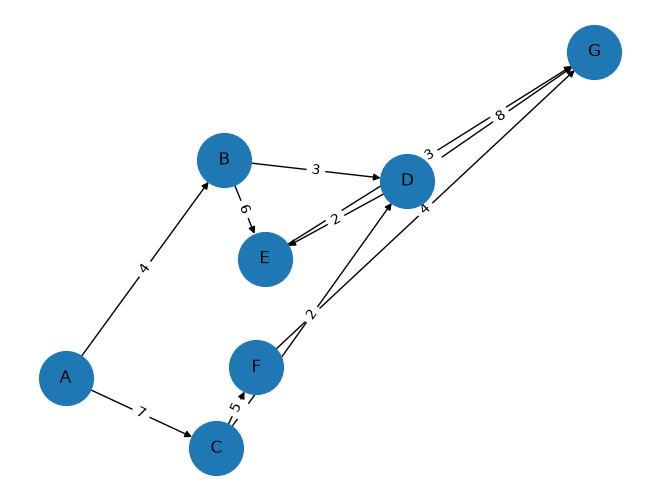

In [6]:
pos = nx.spring_layout(grafo, seed=10)

nx.draw(
    grafo,
    pos,
    with_labels=True,
    node_size=1500,
    arrows=True
)

labels = nx.get_edge_attributes(grafo, "weight")

nx.draw_networkx_edge_labels(
    grafo,
    pos,
    edge_labels=labels
)
plt.show()

In [7]:
# Mostramos las rutas
rutas = list(
    nx.all_simple_paths(
        grafo,
        source="A",
        target="G"
    )
)

# Imprimimos las rutas
for i, ruta in enumerate(rutas, start=1):
    print(f"Ruta {i}: {ruta}")

Ruta 1: ['A', 'B', 'D', 'G']
Ruta 2: ['A', 'B', 'D', 'E', 'G']
Ruta 3: ['A', 'B', 'E', 'G']
Ruta 4: ['A', 'C', 'D', 'G']
Ruta 5: ['A', 'C', 'D', 'E', 'G']
Ruta 6: ['A', 'C', 'F', 'G']


In [8]:
# Calculamos el costo
def costo_ruta(grafo, ruta):
    costo = 0
    for i in range(len(ruta) - 1):
        costo += grafo[ruta[i]][ruta[i + 1]]["weight"]
    return costo

# Imprimimos el costo
for i, ruta in enumerate(rutas, start=1):
    costo = costo_ruta(grafo, ruta)
    print(f"Ruta {i}: {ruta} -> {costo} unidades")

Ruta 1: ['A', 'B', 'D', 'G'] -> 15 unidades
Ruta 2: ['A', 'B', 'D', 'E', 'G'] -> 12 unidades
Ruta 3: ['A', 'B', 'E', 'G'] -> 13 unidades
Ruta 4: ['A', 'C', 'D', 'G'] -> 17 unidades
Ruta 5: ['A', 'C', 'D', 'E', 'G'] -> 14 unidades
Ruta 6: ['A', 'C', 'F', 'G'] -> 16 unidades


In [10]:
# Elegir la ruta más corta

costos = [
    costo_ruta(grafo, ruta)
    for ruta in rutas
]

mejor_ruta = costos.index(min(costos))

In [11]:
# Imprimir la mejor ruta

print(f"La mejor ruta es: {mejor_ruta + 1}")
print(f"El camino costo es: {costos[mejor_ruta]}")

La mejor ruta es: 2
El camino costo es: 12
